# 🏋️ Milestone 1 — EDA: Gym Members Exercise Tracking

**Mata kuliah:** Statistika dan Probabilitas (TIF1501) · Uniska MAB Banjarmasin
**Nama:** Fadliatul Amaliyah · **NIM:** 2410010585

## Deskripsi singkat
Dataset berisi catatan latihan **973 anggota gym**: data tubuh (umur, berat, tinggi, BMI, persentase lemak), detak jantung (maksimum, rata-rata, istirahat), sesi latihan (durasi, kalori terbakar, jenis latihan, frekuensi per minggu), asupan air, dan tingkat pengalaman.

- **Sumber:** Kaggle — *Gym Members Exercise Dataset* (file `gym_members_exercise_tracking.csv`).
- **Konteks bisnis:** pengelola gym ingin tahu faktor apa yang berkaitan dengan kalori terbakar dan persentase lemak tubuh, supaya program latihan dan saran anggota lebih tepat sasaran.
- **Syarat Milestone 1:** ≥ 500 baris ✅ (973) · ≥ 5 kolom ✅ (15) · bukan Mall Customers ✅.

## Daftar isi (7 langkah EDA)
1. Load dan inspeksi · 2. Missing dan duplikat · 3. Ukuran pemusatan · 4. Ukuran sebaran · 5. Grafik 1 variabel · 6. Grafik 2 variabel (+ dashboard Plotly) · 7. Insight dan hipotesis Milestone 2

## Langkah 0 — Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.width', 200)
print('✅ Library siap.', 'pandas', pd.__version__, '| numpy', np.__version__)

✅ Library siap. pandas 3.0.6 | numpy 2.5.4


## Langkah 1 — Load dan Inspeksi

Unggah `gym_members_exercise_tracking.csv` saat tombol **Choose Files** muncul di Colab (atau letakkan file di folder yang sama dengan notebook).

In [2]:
CSV = 'gym_members_exercise_tracking.csv'
if not os.path.exists(CSV):
    try:
        from google.colab import files
        print('Pilih file gym_members_exercise_tracking.csv dari komputer Anda...')
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'{CSV} tidak ditemukan. Letakkan di folder yang sama dengan notebook.')

raw = pd.read_csv(CSV)
print('Kolom asli:'); print(list(raw.columns))

# Nama pendek agar kode mudah dibaca
df = raw.copy()
df.columns = ['age', 'gender', 'weight', 'height', 'max_bpm', 'avg_bpm', 'rest_bpm',
              'duration', 'calories', 'workout', 'fat_pct', 'water', 'freq', 'exp', 'bmi']
df['exp_label'] = df['exp'].map({1: 'Beginner', 2: 'Intermediate', 3: 'Expert'})

num_cols = ['age', 'weight', 'height', 'max_bpm', 'avg_bpm', 'rest_bpm', 'duration',
            'calories', 'fat_pct', 'water', 'freq', 'bmi']

print(f'\nShape: {raw.shape[0]} baris × {raw.shape[1]} kolom')
print('✅ ≥ 500 baris :', raw.shape[0] >= 500)
print('✅ ≥ 5 kolom   :', raw.shape[1] >= 5)
display(df.head())

Kolom asli:
['Age', 'Gender', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)', 'Calories_Burned', 'Workout_Type', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)', 'Experience_Level', 'BMI']

Shape: 973 baris × 15 kolom
✅ ≥ 500 baris : True
✅ ≥ 5 kolom   : True
   age  gender  weight  height  max_bpm  avg_bpm  rest_bpm  duration  calories   workout  fat_pct  water  freq  exp   bmi     exp_label
0   56    Male   88.30    1.71      180      157        60      1.69  1,313.00      Yoga    12.60   3.50     4    3 30.20        Expert
1   46  Female   74.90    1.53      179      151        66      1.30    883.00      HIIT    33.90   2.10     4    2 32.00  Intermediate
2   32  Female   68.10    1.66      167      122        54      1.11    677.00    Cardio    33.40   2.30     4    2 24.71  Intermediate
3   25    Male   53.20    1.70      190      164        56      0.59    532.00  Strength    28.80   2.10     3    1 18.41  

In [3]:
print('=== TIPE DATA ===')
print(df.dtypes)
print('''
=== JENIS DATA (klasifikasi Modul 1) ===
Nominal : gender, workout
Ordinal : exp (1 = Beginner, 2 = Intermediate, 3 = Expert)
Rasio   : age, weight, height, max_bpm, avg_bpm, rest_bpm, duration, calories,
          fat_pct, water, freq (hari/minggu), bmi''')
print('\n=== STATISTIK RINGKAS ===')
display(df[num_cols].describe().T)

=== TIPE DATA ===
age            int64
gender           str
weight       float64
height       float64
max_bpm        int64
avg_bpm        int64
rest_bpm       int64
duration     float64
calories     float64
workout          str
fat_pct      float64
water        float64
freq           int64
exp            int64
bmi          float64
exp_label        str
dtype: object

=== JENIS DATA (klasifikasi Modul 1) ===
Nominal : gender, workout
Ordinal : exp (1 = Beginner, 2 = Intermediate, 3 = Expert)
Rasio   : age, weight, height, max_bpm, avg_bpm, rest_bpm, duration, calories,
          fat_pct, water, freq (hari/minggu), bmi

=== STATISTIK RINGKAS ===
          count   mean    std    min    25%    50%      75%      max
age      973.00  38.68  12.18  18.00  28.00  40.00    49.00    59.00
weight   973.00  73.85  21.21  40.00  58.10  70.00    86.00   129.90
height   973.00   1.72   0.13   1.50   1.62   1.71     1.80     2.00
max_bpm  973.00 179.88  11.53 160.00 170.00 180.00   190.00   199.00
avg_

## Langkah 2 — Missing Value, Duplikat, dan Kualitas Data

In [4]:
print('Total missing :', df.isnull().sum().sum())
print('Baris duplikat:', df.duplicated().sum())

print('\n=== Kategori ===')
for c in ['gender', 'workout', 'exp_label', 'freq']:
    print(f'\n{c}:'); print(df[c].value_counts().sort_index().to_string())

print('\n=== Cek konsistensi data ===')
bmi_calc = df['weight'] / df['height'] ** 2
print('Selisih BMI (data vs berat/tinggi²) maksimum :', round((df['bmi'] - bmi_calc).abs().max(), 4))
print('Baris dengan max_bpm < avg_bpm               :', (df['max_bpm'] < df['avg_bpm']).sum())
print('Baris dengan avg_bpm < rest_bpm              :', (df['avg_bpm'] < df['rest_bpm']).sum())
print('Nilai ≤ 0 pada kolom numerik                 :', (df[num_cols] <= 0).sum().sum())

df['bmi_cat'] = pd.cut(df['bmi'], [0, 18.5, 25, 30, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'], right=False)
print('\nKategori BMI (kolom baru bmi_cat):'); print(df['bmi_cat'].value_counts().sort_index().to_string())

Total missing : 0
Baris duplikat: 0

=== Kategori ===

gender:
gender
Female    462
Male      511

workout:
workout
Cardio      255
HIIT        221
Strength    258
Yoga        239

exp_label:
exp_label
Beginner        376
Expert          191
Intermediate    406

freq:
freq
2    197
3    368
4    306
5    102

=== Cek konsistensi data ===
Selisih BMI (data vs berat/tinggi²) maksimum : 0.005
Baris dengan max_bpm < avg_bpm               : 23
Baris dengan avg_bpm < rest_bpm              : 0
Nilai ≤ 0 pada kolom numerik                 : 0

Kategori BMI (kolom baru bmi_cat):
bmi_cat
Underweight    168
Normal         370
Overweight     243
Obese          192


**Temuan kualitas data:** tidak ada missing dan tidak ada duplikat. BMI konsisten dengan berat dan tinggi (selisih maksimum 0,005). Ada **23 baris dengan `max_bpm` lebih kecil daripada `avg_bpm`**, yang secara fisiologis janggal (detak maksimum seharusnya tidak lebih rendah dari rata-rata). Baris ini **dicatat, tidak dibuang**, karena jumlahnya kecil (sekitar 2,4%) dan tidak memengaruhi analisis utama (kalori, durasi, lemak). Tetap disebutkan sebagai keterbatasan data.

## Langkah 3 — Ukuran Pemusatan (Central Tendency)

In [5]:
rows = []
for c in num_cols:
    mean, med = df[c].mean(), df[c].median()
    mode = df[c].mode().iloc[0]
    diff = (mean - med) / med * 100
    bentuk = 'SIMETRIS' if abs(diff) < 2 else ('MIRING KANAN' if diff > 0 else 'MIRING KIRI')
    rows.append([c, mean, med, mode, diff, bentuk])

central = pd.DataFrame(rows, columns=['kolom', 'mean', 'median', 'modus', 'selisih_%', 'bentuk'])
display(central)
print('Cara baca: selisih_% = (mean - median) / median × 100. Di bawah 2% dianggap simetris.')
print('Modus gender :', df['gender'].mode().iloc[0], '| Modus workout:', df['workout'].mode().iloc[0])

       kolom   mean  median  modus  selisih_%        bentuk
0        age  38.68   40.00  43.00      -3.29   MIRING KIRI
1     weight  73.85   70.00  57.70       5.51  MIRING KANAN
2     height   1.72    1.71   1.62       0.74      SIMETRIS
3    max_bpm 179.88  180.00 198.00      -0.06      SIMETRIS
4    avg_bpm 143.77  143.00 132.00       0.54      SIMETRIS
5   rest_bpm  62.22   62.00  50.00       0.36      SIMETRIS
6   duration   1.26    1.26   1.03      -0.28      SIMETRIS
7   calories 905.42  893.00 883.00       1.39      SIMETRIS
8    fat_pct  24.98   26.20  28.10      -4.67   MIRING KIRI
9      water   2.63    2.60   3.50       1.02      SIMETRIS
10      freq   3.32    3.00   3.00      10.72  MIRING KANAN
11       bmi  24.91   24.16  23.53       3.11  MIRING KANAN
Cara baca: selisih_% = (mean - median) / median × 100. Di bawah 2% dianggap simetris.
Modus gender : Male | Modus workout: Strength


## Langkah 4 — Ukuran Sebaran (Dispersion)

In [6]:
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile(.25), df[c].quantile(.75)
    cv = df[c].std() / df[c].mean() * 100
    kat = 'rendah' if cv < 15 else ('sedang' if cv <= 30 else 'tinggi')
    rows.append([c, df[c].max() - df[c].min(), df[c].std(), q1, q3, q3 - q1, cv, kat, df[c].skew()])

disp = pd.DataFrame(rows, columns=['kolom', 'range', 'std', 'Q1', 'Q3', 'IQR', 'CV_%', 'kategori_CV', 'skewness'])
display(disp)

print('\n=== Outlier (aturan 1.5 × IQR) ===')
for c in num_cols:
    q1, q3 = df[c].quantile(.25), df[c].quantile(.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    if n_out:
        print(f'{c:9s}: batas [{lo:8.2f}, {hi:8.2f}] → {n_out} outlier')
print('(kolom yang tidak tercetak = 0 outlier)')

       kolom    range    std     Q1       Q3    IQR  CV_% kategori_CV  skewness
0        age    41.00  12.18  28.00    49.00  21.00 31.49      tinggi     -0.08
1     weight    89.90  21.21  58.10    86.00  27.90 28.72      sedang      0.77
2     height     0.50   0.13   1.62     1.80   0.18  7.41      rendah      0.34
3    max_bpm    39.00  11.53 170.00   190.00  20.00  6.41      rendah     -0.04
4    avg_bpm    49.00  14.35 131.00   156.00  25.00  9.98      rendah      0.09
5   rest_bpm    24.00   7.33  56.00    68.00  12.00 11.78      rendah     -0.07
6   duration     1.50   0.34   1.04     1.46   0.42 27.30      sedang      0.03
7   calories 1,480.00 272.64 720.00 1,076.00 356.00 30.11      tinggi      0.28
8    fat_pct    25.00   6.26  21.30    29.30   8.00 25.06      sedang     -0.64
9      water     2.20   0.60   2.20     3.10   0.90 22.85      sedang      0.07
10      freq     3.00   0.91   3.00     4.00   1.00 27.49      sedang      0.15
11       bmi    37.52   6.66  20.11    2

## Langkah 5 — Grafik 1 Variabel (Univariat)

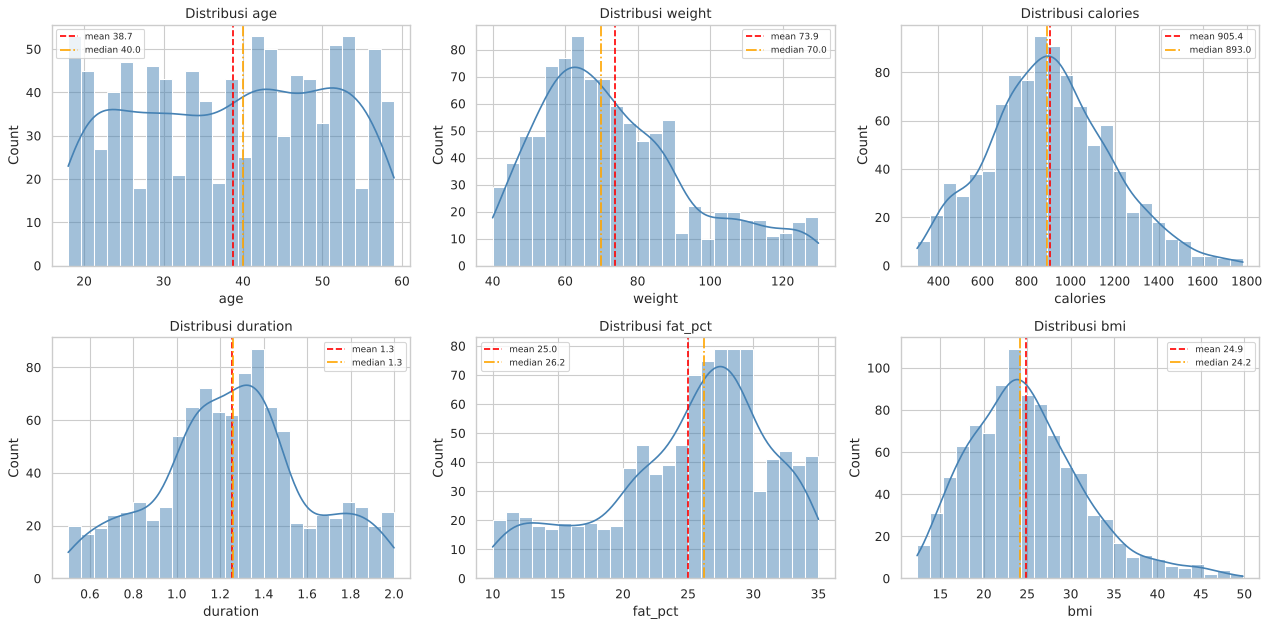

In [7]:
# VISUALISASI 1 — Histogram + KDE (garis merah = mean, oranye = median)
cols = ['age', 'weight', 'calories', 'duration', 'fat_pct', 'bmi']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], bins=25, kde=True, ax=ax, color='steelblue')
    ax.axvline(df[c].mean(),   color='red',    ls='--', label=f'mean {df[c].mean():.1f}')
    ax.axvline(df[c].median(), color='orange', ls='-.', label=f'median {df[c].median():.1f}')
    ax.set_title(f'Distribusi {c}'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

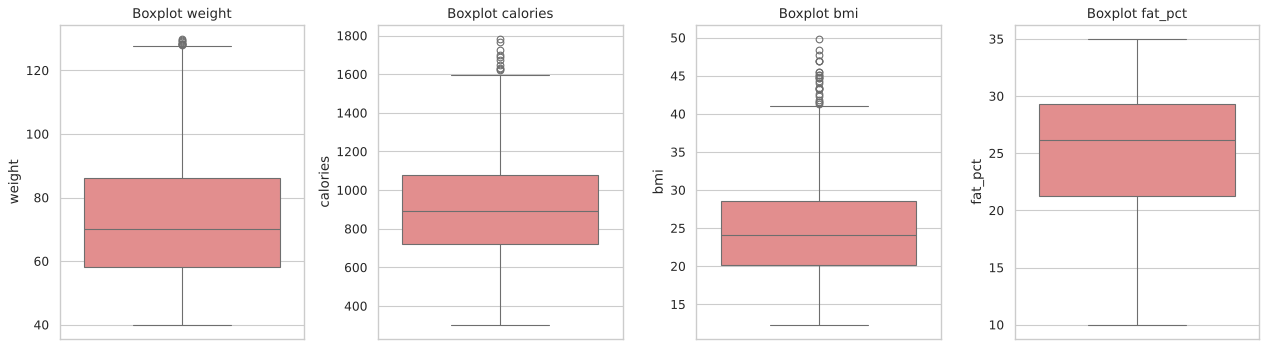

In [8]:
# VISUALISASI 2 — Boxplot (titik di luar kumis = outlier)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, c in zip(axes, ['weight', 'calories', 'bmi', 'fat_pct']):
    sns.boxplot(y=df[c], ax=ax, color='lightcoral'); ax.set_title(f'Boxplot {c}')
plt.tight_layout(); plt.show()

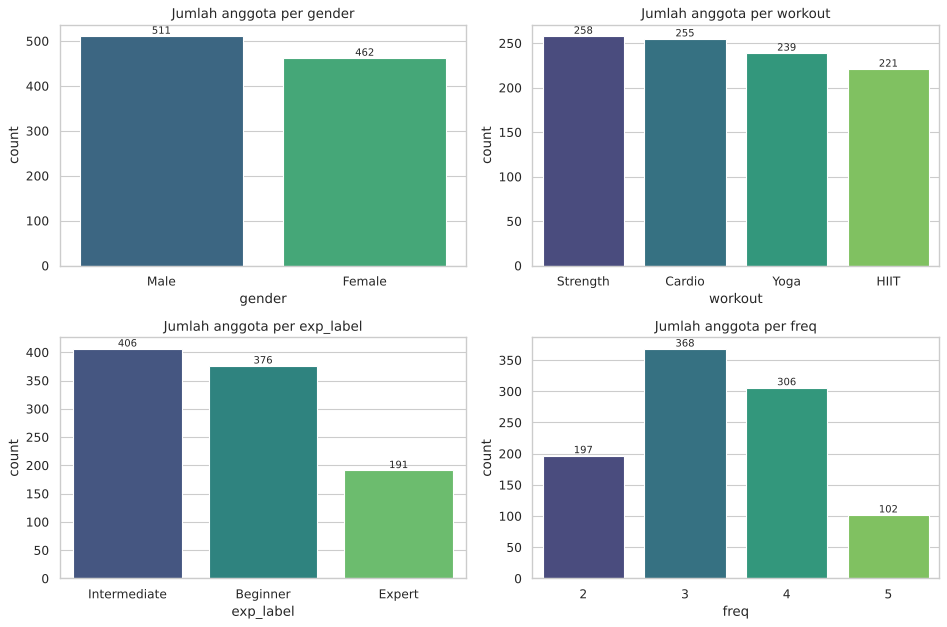

In [9]:
# VISUALISASI 3 — Komposisi variabel kategorik
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), ['gender', 'workout', 'exp_label', 'freq']):
    order = sorted(df[c].unique()) if c == 'freq' else df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax, palette='viridis')
    ax.set_title(f'Jumlah anggota per {c}')
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

## Langkah 6 — Grafik 2 Variabel (Bivariat)

Korelasi dengan calories (urut):
duration    0.91
freq        0.58
water       0.36
avg_bpm     0.34
weight      0.10
height      0.09
bmi         0.06
rest_bpm    0.02
max_bpm     0.00
age        -0.15
fat_pct    -0.60

Korelasi dengan fat_pct (urut):
calories   -0.60
water      -0.59
duration   -0.58
freq       -0.54
height     -0.24
weight     -0.23
bmi        -0.12
rest_bpm   -0.02
max_bpm    -0.01
avg_bpm    -0.01
age         0.00


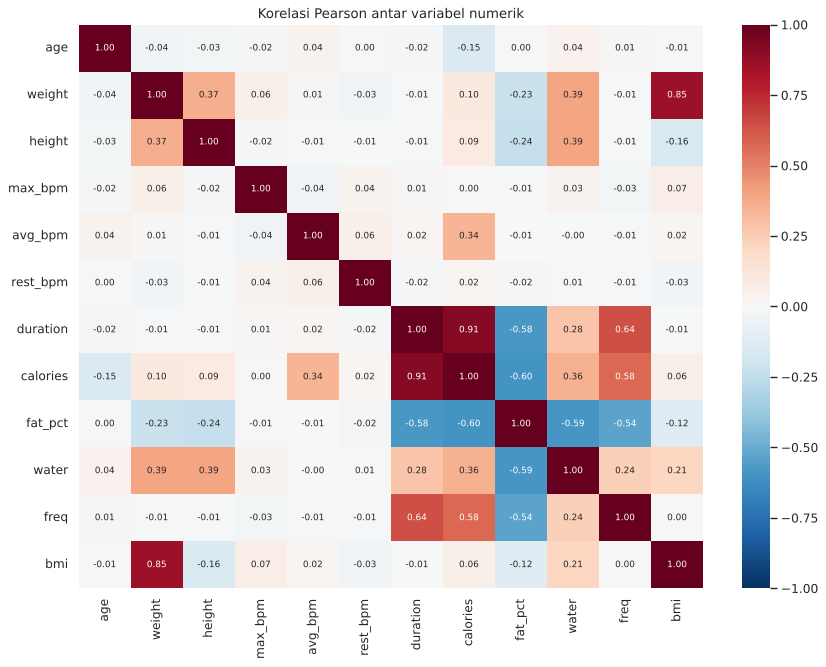

In [10]:
# VISUALISASI 4 — Heatmap korelasi semua variabel numerik
corr = df[num_cols].corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, annot_kws={'size': 8})
plt.title('Korelasi Pearson antar variabel numerik'); plt.tight_layout(); plt.show()
print('Korelasi dengan calories (urut):'); print(corr['calories'].drop('calories').sort_values(ascending=False).round(3).to_string())
print('\nKorelasi dengan fat_pct (urut):'); print(corr['fat_pct'].drop('fat_pct').sort_values().round(3).to_string())

r (duration, calories) = 0.908


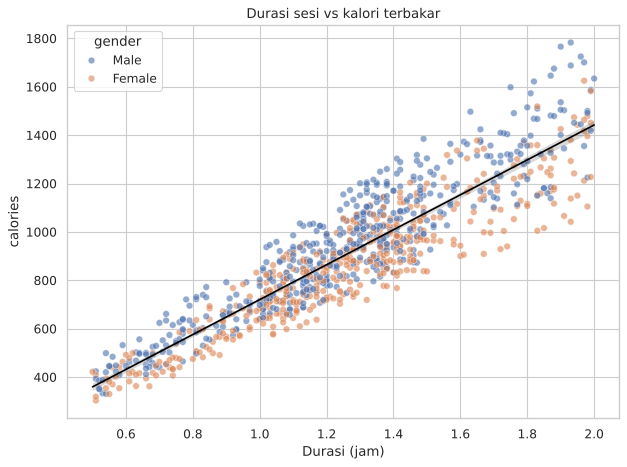

In [11]:
# VISUALISASI 5 — Scatter durasi vs kalori (warna = gender) + garis tren
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='duration', y='calories', hue='gender', alpha=.6)
sns.regplot(data=df, x='duration', y='calories', scatter=False, color='black', line_kws={'lw': 1.5})
plt.title('Durasi sesi vs kalori terbakar'); plt.xlabel('Durasi (jam)'); plt.tight_layout(); plt.show()
print('r (duration, calories) =', round(df['duration'].corr(df['calories']), 3))

          count   mean  median    std
workout                              
Cardio      255 884.51  888.00 270.20
HIIT        221 925.81  920.00 274.49
Strength    258 910.70  904.50 270.26
Yoga        239 903.19  876.00 276.14

        count   mean  median    std
gender                             
Female    462 862.25  867.00 249.61
Male      511 944.46  937.00 286.59


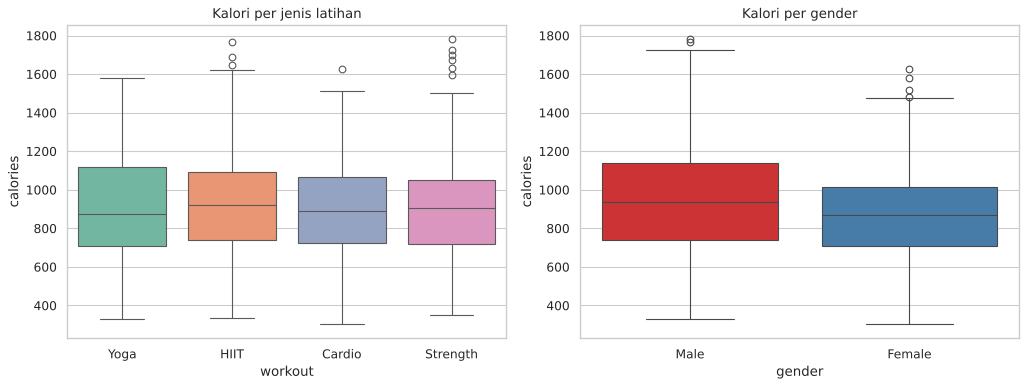

In [12]:
# VISUALISASI 6 — Kalori terbakar per jenis latihan dan per gender
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x='workout', y='calories', ax=axes[0], palette='Set2'); axes[0].set_title('Kalori per jenis latihan')
sns.boxplot(data=df, x='gender', y='calories', ax=axes[1], palette='Set1'); axes[1].set_title('Kalori per gender')
plt.tight_layout(); plt.show()
print(df.groupby('workout')['calories'].agg(['count', 'mean', 'median', 'std']).round(2))
print()
print(df.groupby('gender')['calories'].agg(['count', 'mean', 'median', 'std']).round(2))

              fat_pct  freq  duration  calories  water
exp_label                                             
Beginner        27.63  2.48      1.01    726.38   2.53
Intermediate    27.31  3.53      1.25    901.92   2.48
Expert          14.79  4.53      1.76  1,265.34   3.12


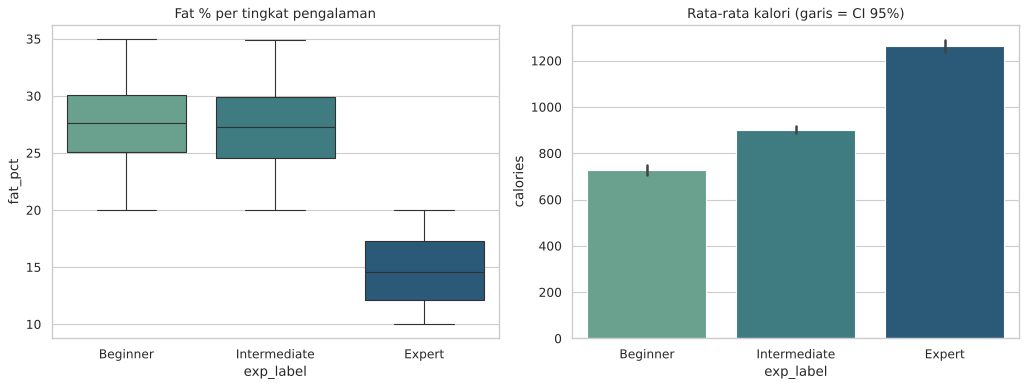

In [13]:
# VISUALISASI 7 — Persentase lemak berdasarkan tingkat pengalaman
order = ['Beginner', 'Intermediate', 'Expert']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x='exp_label', y='fat_pct', order=order, ax=axes[0], palette='crest'); axes[0].set_title('Fat % per tingkat pengalaman')
sns.barplot(data=df, x='exp_label', y='calories', order=order, errorbar=('ci', 95), ax=axes[1], palette='crest'); axes[1].set_title('Rata-rata kalori (garis = CI 95%)')
plt.tight_layout(); plt.show()
print(df.groupby('exp_label')[['fat_pct', 'freq', 'duration', 'calories', 'water']].mean().reindex(order).round(2))

      fat_pct   bmi  calories
freq                         
2       27.44 25.01    726.38
3       27.59 24.68    821.44
4       23.69 25.25    997.64
5       14.66 24.54  1,277.57


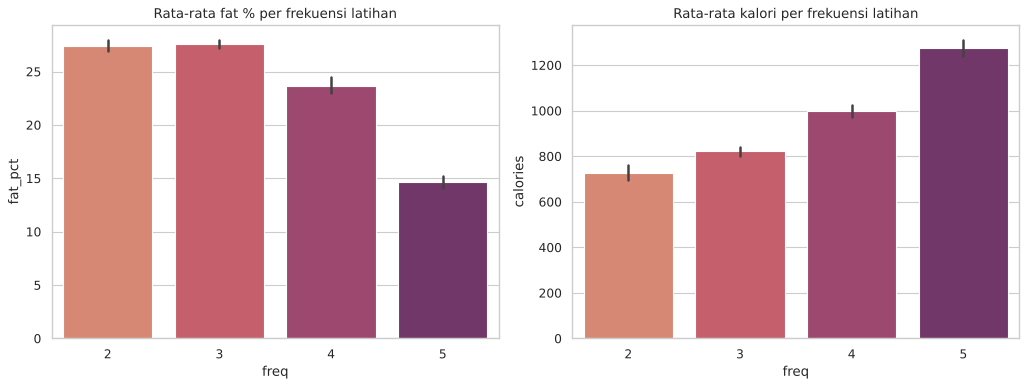

In [14]:
# VISUALISASI 8 — Frekuensi latihan per minggu vs fat% dan kalori
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=df, x='freq', y='fat_pct', errorbar=('ci', 95), ax=axes[0], palette='flare'); axes[0].set_title('Rata-rata fat % per frekuensi latihan')
sns.barplot(data=df, x='freq', y='calories', errorbar=('ci', 95), ax=axes[1], palette='flare'); axes[1].set_title('Rata-rata kalori per frekuensi latihan')
plt.tight_layout(); plt.show()
print(df.groupby('freq')[['fat_pct', 'bmi', 'calories']].mean().round(2))

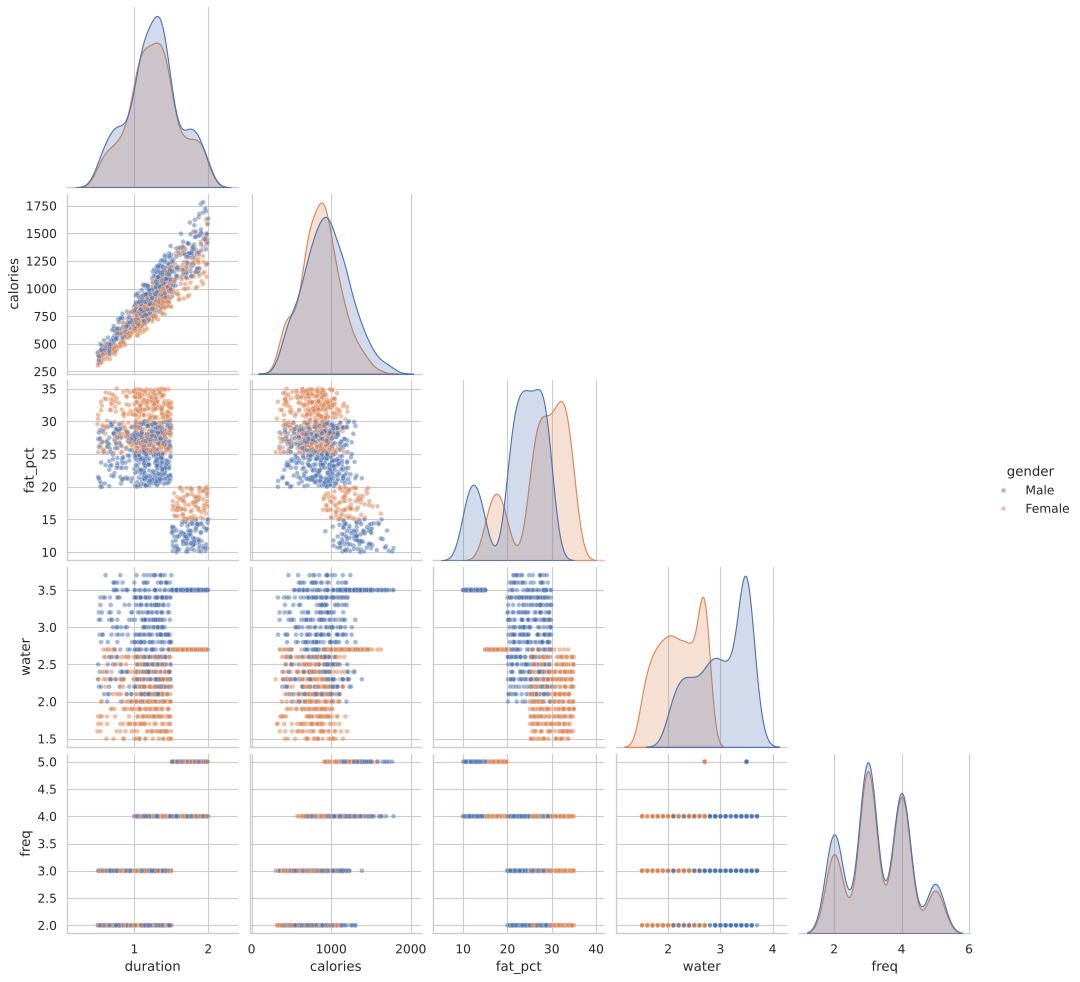

In [15]:
# BONUS — Pairplot variabel utama (warna = gender)
sns.pairplot(df, vars=['duration', 'calories', 'fat_pct', 'water', 'freq'], hue='gender', diag_kind='kde', corner=True, plot_kws={'alpha': .5, 's': 18})
plt.show()

### Dashboard Interaktif (Plotly)

Dashboard berisi **4 chart** (syarat minimal 2). HTML disimpan ke `dashboard_milestone1.html` agar bisa diunggah ke GitHub. Arahkan kursor ke grafik untuk melihat nilai.

> ⚠️ Cell Plotly **tidak dijalankan** saat saya menyiapkan file ini (Plotly tidak tersedia di lingkungan saya). Jalankan di Colab untuk melihat dashboard interaktifnya. Versi statis (gambar) ada di cell sesudahnya.

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Durasi sesi vs kalori terbakar', 'Kalori per jenis latihan',
                    'Fat % per tingkat pengalaman', 'Rata-rata kalori per frekuensi latihan'),
    specs=[[{'type': 'xy'}, {'type': 'xy'}], [{'type': 'xy'}, {'type': 'xy'}]]
)

# 1) Scatter durasi vs kalori
for g, col in [('Male', '#264653'), ('Female', '#e76f51')]:
    sub = df[df['gender'] == g]
    fig.add_trace(go.Scatter(x=sub['duration'], y=sub['calories'], mode='markers', name=g,
                             marker=dict(color=col, opacity=.55, size=6)), row=1, col=1)

# 2) Boxplot kalori per jenis latihan
for w in df['workout'].unique():
    fig.add_trace(go.Box(y=df.loc[df['workout'] == w, 'calories'], name=w, showlegend=False), row=1, col=2)

# 3) Boxplot fat% per pengalaman
for lbl in ['Beginner', 'Intermediate', 'Expert']:
    fig.add_trace(go.Box(y=df.loc[df['exp_label'] == lbl, 'fat_pct'], name=lbl, showlegend=False), row=2, col=1)

# 4) Bar rata-rata kalori per frekuensi
fm = df.groupby('freq')['calories'].mean().round(1)
fig.add_trace(go.Bar(x=[f'{i} hari' for i in fm.index], y=fm.values, marker_color='#6a4c93', showlegend=False), row=2, col=2)

fig.update_layout(height=750, width=1100, title_text='Dashboard EDA — Gym Members Exercise Tracking')
fig.write_html('dashboard_milestone1.html')
print('✅ Dashboard disimpan: dashboard_milestone1.html')
fig.show()

✅ Disimpan: dashboard_static.png


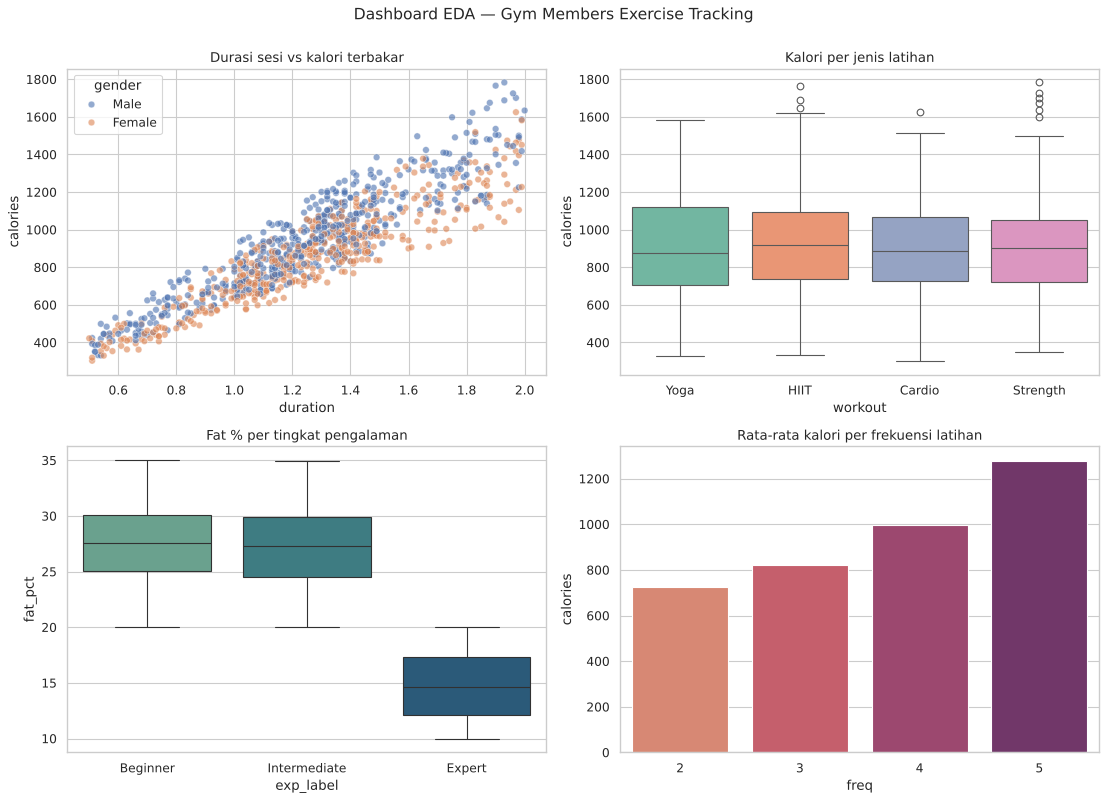

In [16]:
# Versi STATIS dashboard (gambar) — dipakai sebagai screenshot di README
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.scatterplot(data=df, x='duration', y='calories', hue='gender', alpha=.6, ax=axes[0, 0]); axes[0, 0].set_title('Durasi sesi vs kalori terbakar')
sns.boxplot(data=df, x='workout', y='calories', ax=axes[0, 1], palette='Set2'); axes[0, 1].set_title('Kalori per jenis latihan')
sns.boxplot(data=df, x='exp_label', y='fat_pct', order=['Beginner', 'Intermediate', 'Expert'], ax=axes[1, 0], palette='crest'); axes[1, 0].set_title('Fat % per tingkat pengalaman')
sns.barplot(data=df, x='freq', y='calories', errorbar=None, ax=axes[1, 1], palette='flare'); axes[1, 1].set_title('Rata-rata kalori per frekuensi latihan')
plt.suptitle('Dashboard EDA — Gym Members Exercise Tracking', fontsize=14, y=1.0)
plt.tight_layout(); plt.savefig('dashboard_static.png', dpi=110, bbox_inches='tight'); plt.show()
print('✅ Disimpan: dashboard_static.png')

## Langkah 7 — Insight (dengan bukti angka) dan Hipotesis Milestone 2

Setiap insight di bawah **dihitung otomatis dari data**. Pola tiap insight: **temuan + angka bukti + arti untuk bisnis**.

In [17]:
def kekuatan(r):
    a = abs(r)
    return 'sangat kuat' if a >= .8 else 'kuat' if a >= .6 else 'sedang' if a >= .3 else 'lemah'

# ---------- Insight 1: durasi sesi ----------
r_dur = df['duration'].corr(df['calories'])
r_bpm = df['avg_bpm'].corr(df['calories'])
r_wt  = df['weight'].corr(df['calories'])
print(f"INSIGHT 1 — Durasi sesi adalah penentu utama kalori terbakar: korelasi {kekuatan(r_dur)} (r = {r_dur:.3f}).")
print(f"  Pembanding: avg_bpm r = {r_bpm:.3f} ({kekuatan(r_bpm)}), weight r = {r_wt:.3f} ({kekuatan(r_wt)}).")
print(f"  Artinya: durasi sesi adalah faktor yang paling berkaitan dengan kalori terbakar, jauh lebih kuat daripada detak jantung rata-rata (ini hubungan korelasi, bukan bukti sebab-akibat).\n")

# ---------- Insight 2: tingkat pengalaman ----------
g = df.groupby('exp_label')[['fat_pct', 'freq', 'duration', 'calories']].mean()
print(f"INSIGHT 2 — Persentase lemak turun tajam pada tingkat Expert: Beginner {g.loc['Beginner','fat_pct']:.1f}%, Intermediate {g.loc['Intermediate','fat_pct']:.1f}%, Expert {g.loc['Expert','fat_pct']:.1f}%.")
print(f"  Anggota Expert berlatih {g.loc['Expert','freq']:.1f} hari/minggu selama {g.loc['Expert','duration']:.2f} jam dan membakar {g.loc['Expert','calories']:.0f} kalori (Beginner: {g.loc['Beginner','freq']:.1f} hari, {g.loc['Beginner','duration']:.2f} jam, {g.loc['Beginner','calories']:.0f} kalori).")
print(f"  Artinya: konsistensi (frekuensi dan durasi) lebih berkaitan dengan lemak rendah daripada sekadar lama menjadi anggota; program transisi dari Intermediate ke Expert layak didorong.\n")

# ---------- Insight 3: gender ----------
gm = df.groupby('gender')[['calories', 'weight', 'fat_pct', 'duration', 'water']].mean()
print(f"INSIGHT 3 — Pria membakar lebih banyak kalori ({gm.loc['Male','calories']:.0f} vs {gm.loc['Female','calories']:.0f}), lebih berat ({gm.loc['Male','weight']:.1f} vs {gm.loc['Female','weight']:.1f} kg), lemak lebih rendah ({gm.loc['Male','fat_pct']:.1f}% vs {gm.loc['Female','fat_pct']:.1f}%), dan minum lebih banyak ({gm.loc['Male','water']:.2f} vs {gm.loc['Female','water']:.2f} L).")
print(f"  Durasi sesi nyaris sama ({gm.loc['Male','duration']:.2f} vs {gm.loc['Female','duration']:.2f} jam), jadi selisih kalori bukan karena lama latihan.")
print(f"  Artinya: target kalori sebaiknya dibedakan per gender.\n")

# ---------- Insight 4: jenis latihan ----------
wk = df.groupby('workout')['calories'].mean().sort_values()
print(f"INSIGHT 4 — Jenis latihan hampir tidak membedakan kalori: terendah {wk.index[0]} ({wk.iloc[0]:.0f}), tertinggi {wk.index[-1]} ({wk.iloc[-1]:.0f}); selisih hanya {wk.iloc[-1]-wk.iloc[0]:.0f} kalori ({(wk.iloc[-1]-wk.iloc[0])/wk.mean()*100:.1f}% dari rata-rata).")
print(f"  Artinya: pilihan jenis latihan bisa mengikuti minat anggota; yang perlu dijaga adalah durasi dan frekuensi.\n")

# ---------- Insight 5: BMI ----------
r_bmi_fat = df['bmi'].corr(df['fat_pct']); r_bmi_cal = df['bmi'].corr(df['calories'])
cat = df['bmi_cat'].value_counts(normalize=True).mul(100)
print(f"INSIGHT 5 — BMI kurang menggambarkan kebugaran: korelasi BMI dengan fat_pct hanya r = {r_bmi_fat:.3f} dan dengan calories r = {r_bmi_cal:.3f} ({kekuatan(r_bmi_cal)}).")
print(f"  Sebaran kategori BMI: Normal {cat['Normal']:.1f}%, Overweight {cat['Overweight']:.1f}%, Obese {cat['Obese']:.1f}%, Underweight {cat['Underweight']:.1f}%.")
print(f"  Artinya: gunakan fat_pct dan pola latihan, bukan BMI saja, untuk menilai progres anggota.")

INSIGHT 1 — Durasi sesi adalah penentu utama kalori terbakar: korelasi sangat kuat (r = 0.908).
  Pembanding: avg_bpm r = 0.340 (sedang), weight r = 0.095 (lemah).
  Artinya: durasi sesi adalah faktor yang paling berkaitan dengan kalori terbakar, jauh lebih kuat daripada detak jantung rata-rata (ini hubungan korelasi, bukan bukti sebab-akibat).

INSIGHT 2 — Persentase lemak turun tajam pada tingkat Expert: Beginner 27.6%, Intermediate 27.3%, Expert 14.8%.
  Anggota Expert berlatih 4.5 hari/minggu selama 1.76 jam dan membakar 1265 kalori (Beginner: 2.5 hari, 1.01 jam, 726 kalori).
  Artinya: konsistensi (frekuensi dan durasi) lebih berkaitan dengan lemak rendah daripada sekadar lama menjadi anggota; program transisi dari Intermediate ke Expert layak didorong.

INSIGHT 3 — Pria membakar lebih banyak kalori (944 vs 862), lebih berat (85.5 vs 60.9 kg), lemak lebih rendah (22.6% vs 27.7%), dan minum lebih banyak (3.01 vs 2.21 L).
  Durasi sesi nyaris sama (1.25 vs 1.26 jam), jadi selisih ka

### Daftar Hipotesis untuk Milestone 2 (Modul 10)

| No | Insight asal | H₀ | H₁ | Uji yang direncanakan | Asumsi yang dicek |
|---|---|---|---|---|---|
| H1 | Insight 3 (gender) | μ_calories(Male) = μ_calories(Female) | μ_calories(Male) ≠ μ_calories(Female) | Welch two-sample t-test + Cohen's d | Normalitas (Shapiro), varians (Levene), n > 30 |
| H2 | Insight 4 (jenis latihan) | rata-rata calories sama di semua jenis latihan | minimal satu jenis berbeda | One-way ANOVA (+ Tukey HSD bila signifikan) + η² | Normalitas residual, kesamaan varians (Levene) |
| H3 | Insight 2 (pengalaman) | rata-rata fat_pct sama di ketiga tingkat pengalaman | minimal satu tingkat berbeda | One-way ANOVA + Tukey HSD + η² | Normalitas, Levene |

Opsional: H4 (Insight 1) — ρ(duration, calories) = 0 (Pearson r). Semua dengan α = 0,05.

> Catatan: hipotesis di atas masih **dugaan dari EDA**. Pembuktiannya ada di Milestone 2.

## Checklist Milestone 1

- [x] Dataset Kaggle pilihan: 973 baris, 15 kolom, bukan Mall Customers
- [x] Framework EDA 7 langkah lengkap
- [x] 8 visualisasi (3 univariat + 5 bivariat) + pairplot bonus
- [x] Dashboard Plotly (4 chart) + versi statis
- [x] 5 insight dengan angka bukti
- [x] 3 hipotesis (+1 opsional) untuk Milestone 2
- [ ] README.md di-upload (file sudah disiapkan)
- [ ] Repo GitHub ter-commit dan link dikumpulkan lewat LMS